# Chapter 08 · 작은 데이터 분석 프로젝트 완성하기

- 이름: 서지민 (의예과, 2024-14010)
- GitHub ID: jasminmuze
- 작성일: 2026-10-27
- 최종 Notebook URL: https://github.com/jasminmuze/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

수업의 가상 온라인 쇼핑몰 실습 자료로 분석했습니다. 실제 거래나 실제 고객을 대표하는 자료로 해석하지 않습니다.

## 1. 프로젝트 질문과 계산 기준

### 질문 1 — 카테고리별 완료 주문 금액은 어떻게 다른가?
- 대상·범위: 완료 주문 상세 중 고객·상품·주문 키가 연결되고 날짜가 유효한 행
- 지표: `line_total = quantity × unit_price` 합계와 전체 분석 금액 대비 비율
- 완료 기준: 카테고리별 합계가 검증 코호트 총액과 일치

### 질문 2 — 월별 완료 주문 금액과 주문 수는 어떻게 변하는가?
- 지표: 월별 `line_total` 합계와 고유 `order_id` 수
- 완료 기준: 월별 금액 합계가 검증 코호트 총액과 일치
- 날짜 결측 행은 월별 집계에서 빼되 행 수·금액을 따로 기록

### 질문 3 — 완료 주문 구매 금액 상위 고객은 어떤 분포를 보이는가?
- 지표: 익명 고객별 구매 금액, 고유 주문 수, 주문당 평균 구매 금액
- 완료 기준: 고객별 금액 합계가 검증 코호트 총액과 일치
- 공개 표에 원본 고객 ID·이름 등 직접 식별정보를 넣지 않음

금액 분석은 `order_status == "completed"`로 시작합니다. 다만 정제 데이터에서 관계가 끊긴 고객·상품·주문 키와 날짜 결측이 실제로 확인되어, 필수 키가 연결되고 날짜가 유효한 행만 공통 분석 코호트로 사용합니다. 금액 단위는 실습 CSV 기준 원으로 가정하며 회계상 순매출로 해석하지 않습니다.

## 2. 입력 데이터와 전처리 검증

원본은 `practice/chapter05/data/raw/`의 고객·상품·주문·주문상세 CSV 4개이며, 정제본은 `data/processed/`에서 읽었습니다.

| 데이터 | 원본 행×열 | 정제 행×열 | 정제 후 주요 컬럼 |
|---|---:|---:|---|
| 고객 | 152×6 | 150×6 | customer_id, name, gender, age, city, signup_date |
| 상품 | 102×4 | 96×4 | product_id, product_name, category, price |
| 주문 | 302×5 | 300×7 | order_id, customer_id, order_date, payment_method, order_status, order_month, order_dayofweek |
| 주문상세 | 765×5 | 752×6 | order_item_id, order_id, product_id, quantity, unit_price, line_total |

원본 고객 자료에는 나이·도시 결측이 있었고 Chapter 05 기록에 따라 나이는 중앙값, 도시는 `Unknown`으로 처리했습니다. 문자열 정리, 중복 처리, 날짜·숫자 자료형 정리, 월·요일 및 `line_total` 파생이 반영되어 있습니다. 행 수 감소는 확인했지만 건별 삭제 로그가 없어 어떤 개별 행이 각 규칙으로 제거됐는지는 재구성할 수 없습니다.

### 해석과 한계
정제 완료가 관계 무결성을 뜻하지는 않습니다. 아래에서 전체 미매칭 키를 공개하고, 분석 표에서는 모든 필수 키가 연결되는 행만 사용합니다. 데이터는 교육용 생성 자료입니다.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, SVG

def find_root(start):
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "practice" / "chapter05" / "data" / "raw").exists() and (p / "data" / "processed").exists():
            return p
    raise FileNotFoundError("저장소 루트에서 raw/processed 데이터 폴더를 찾지 못했습니다.")

PROJECT_ROOT = find_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "practice" / "chapter05" / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
names = ["customers", "products", "orders", "order_items"]
raw = {n: pd.read_csv(RAW_DIR / f"{n}.csv") for n in names}
clean = {n: pd.read_csv(PROCESSED_DIR / f"{n}_clean.csv") for n in names}
print("프로젝트 루트:", PROJECT_ROOT)
print("원본/정제 데이터 읽기: 완료")

프로젝트 루트: (저장소 루트)
원본/정제 데이터 읽기: 완료

In [2]:
summary = []
for n in names:
    a, b = raw[n], clean[n]
    summary.append({
        "dataset": n, "raw_rows": len(a), "raw_columns": len(a.columns),
        "clean_rows": len(b), "clean_columns": len(b.columns),
        "raw_missing_cells": int(a.isna().sum().sum()),
        "raw_duplicate_rows": int(a.duplicated().sum()),
        "clean_missing_cells": int(b.isna().sum().sum()),
        "clean_duplicate_rows": int(b.duplicated().sum()),
    })
dataset_summary = pd.DataFrame(summary)
display(dataset_summary)

dataset       raw_rows  raw_columns  clean_rows  clean_columns  raw_missing_cells  raw_duplicate_rows  clean_missing_cells  clean_duplicate_rows
customers          152            6         150              6                  6                   2                    0                    0
products           102            4          96              4                  0                   2                    0                    0
orders             302            5         300              7                  0                   2                    3                    0
order_items        765            5         752              6                  0                   2                    0                    0

## 3. PK / FK 및 안전한 병합

PK 후보는 네 정제 테이블 모두 결측 0건·중복 0건입니다. 그러나 정제본의 FK 점검은 0건 조건을 통과하지 못했습니다.

| 관계 | 미매칭 | 입력 전체 |
|---|---:|---|
| orders.customer_id → customers.customer_id | 2 | FAIL |
| order_items.order_id → orders.order_id | 2 | FAIL |
| order_items.product_id → products.product_id | 26 | FAIL |

각 테이블 부모 키가 유일한지 확인한 뒤 `validate="many_to_one"`과 `indicator=True`로 병합합니다. 병합 전후 행 수와 미매칭 건수를 확인합니다. 연결이 끊긴 행을 완전한 완료 주문 데이터로 단정하지 않고, 검증된 코호트에서만 후속 집계합니다.

In [3]:
pk = {"customers":"customer_id","products":"product_id","orders":"order_id","order_items":"order_item_id"}
pk_rows = []
for n, key in pk.items():
    df = clean[n]
    pk_rows.append({"table":n,"key":key,"missing":int(df[key].isna().sum()),
                    "duplicates":int(df[key].duplicated().sum())})
pk_checks = pd.DataFrame(pk_rows)
customer_ids = set(clean["customers"]["customer_id"].dropna())
product_ids = set(clean["products"]["product_id"].dropna())
order_ids = set(clean["orders"]["order_id"].dropna())
fk_checks = pd.DataFrame([
    {"relationship":"orders.customer_id → customers.customer_id","unmatched":int((~clean["orders"]["customer_id"].isin(customer_ids)).sum())},
    {"relationship":"order_items.order_id → orders.order_id","unmatched":int((~clean["order_items"]["order_id"].isin(order_ids)).sum())},
    {"relationship":"order_items.product_id → products.product_id","unmatched":int((~clean["order_items"]["product_id"].isin(product_ids)).sum())},
])
pk_checks["status"] = np.where((pk_checks["missing"]==0)&(pk_checks["duplicates"]==0),"PASS","FAIL")
fk_checks["status"] = np.where(fk_checks["unmatched"]==0,"PASS","FAIL")
display(pk_checks)
display(fk_checks)

PK checks:
table         key             missing  duplicates  status
customers     customer_id          0           0   PASS
products      product_id           0           0   PASS
orders        order_id             0           0   PASS
order_items   order_item_id        0           0   PASS

FK checks:
relationship                                      unmatched  status
orders.customer_id → customers.customer_id              2   FAIL
order_items.order_id → orders.order_id                   2   FAIL
order_items.product_id → products.product_id            26   FAIL

## 4. 안전한 병합 및 계산 검증

모든 연결을 `left merge`로 수행해 탈락 여부를 보존하고, 관계를 `many_to_one`으로 검증합니다. `line_total`도 `quantity × unit_price`로 다시 계산합니다. 분석 코호트에서 제외되는 값은 사유별로 금액을 남깁니다.

In [4]:
items = clean["order_items"].copy()
orders_df, products_df, customers_df = clean["orders"], clean["products"], clean["customers"]
items["calculated_line_total"] = items["quantity"] * items["unit_price"]
line_mismatch = int((~np.isclose(items["line_total"], items["calculated_line_total"])).sum())
joined = items.merge(orders_df, on="order_id", how="left", validate="many_to_one", indicator="order_match")
joined = joined.merge(products_df[["product_id","category"]], on="product_id", how="left", validate="many_to_one", indicator="product_match")
joined = joined.merge(customers_df[["customer_id"]], on="customer_id", how="left", validate="many_to_one", indicator="customer_match")
merge_rows_preserved = len(joined) == len(items)
completed = joined.loc[joined["order_status"].eq("completed")].copy()
completed_source_total = int(completed["line_total"].sum())
bad_customer = completed["customer_match"].ne("both")
bad_product = completed["product_match"].ne("both")
bad_date = completed["order_date"].isna()
analysis = completed.loc[~(bad_customer | bad_product | bad_date)].copy()
analysis["category_clean"] = analysis["category"].astype(str).str.strip().replace(
    {"생활 용품":"생활용품","뷰 티":"뷰티","전자 기기":"전자기기"})
analysis["order_date"] = pd.to_datetime(analysis["order_date"], errors="coerce")
analysis["order_month"] = analysis["order_date"].dt.to_period("M").astype(str)
exclusions = pd.DataFrame([
    {"reason":"고객 FK 미매칭","rows":int(bad_customer.sum()),"amount":int(completed.loc[bad_customer,"line_total"].sum())},
    {"reason":"상품 FK 미매칭 (고객 연결 완료)","rows":int((~bad_customer & bad_product).sum()),"amount":int(completed.loc[~bad_customer & bad_product,"line_total"].sum())},
    {"reason":"주문 날짜 결측 (키 연결 완료)","rows":int((~bad_customer & ~bad_product & bad_date).sum()),"amount":int(completed.loc[~bad_customer & ~bad_product & bad_date,"line_total"].sum())},
])
display(exclusions)
print("completed source:",len(completed),"행 /",f"{completed_source_total:,}원")
print("검증된 분석 코호트:",len(analysis),"행 /",f"{int(analysis['line_total'].sum()):,}원")
print("line_total 불일치:",line_mismatch,"| 병합 행 수 보존:",merge_rows_preserved)

reason                              rows      amount
고객 FK 미매칭                         1      376,000
상품 FK 미매칭 (고객 연결 완료)         16    4,015,000
주문 날짜 결측 (키 연결 완료)            6    1,903,000

completed source: 446 행 / 141,340,000원
검증된 분석 코호트: 423 행 / 135,046,000원
line_total 불일치: 0 | 병합 행 수 보존: True

## 5. 핵심 EDA 결과

### 결과 1 — 카테고리별 금액
검증 코호트에서 패션 32,940,000원, 식품 24,687,000원, 전자기기 20,445,000원 순입니다. 공백 차이만 있는 카테고리 표기는 사전에 적은 정규화 사전으로 통합했습니다. 이는 완료 금액 구성의 차이를 보여주지만 판매수량·마진·고객 선호의 원인을 증명하지 않습니다.

### 결과 2 — 월별 금액과 주문 수
검증 코호트에서 2026년 8월은 16,668,000원, 15건으로 관찰 월 중 가장 높습니다. 2026년 9~12월 데이터가 없어 0으로 바꾸거나 선으로 잇지 않았습니다. 2027년 1월은 1건뿐이라 추세로 일반화하지 않습니다.

### 결과 3 — 익명 고객 구매
익명 순위 1위는 6,702,000원(3건)입니다. 이 순위는 해당 실습 데이터의 기술통계이며 충성도·수익성·미래 구매를 뜻하지 않습니다.

In [5]:
completed_total = int(analysis["line_total"].sum())
category_sales = (analysis.groupby("category_clean",as_index=False)
                  .agg(total_sales=("line_total","sum"),item_rows=("order_item_id","count"))
                  .sort_values("total_sales",ascending=False))
category_sales["share_pct"] = category_sales["total_sales"] / completed_total * 100
monthly_sales = (analysis.groupby("order_month",as_index=False)
                 .agg(total_sales=("line_total","sum"),order_count=("order_id","nunique"))
                 .sort_values("order_month"))
customer_internal = (analysis.groupby("customer_id",as_index=False)
                     .agg(total_sales=("line_total","sum"),order_count=("order_id","nunique")))
customer_internal["avg_order_value"] = customer_internal["total_sales"] / customer_internal["order_count"]
customer_internal = customer_internal.sort_values("total_sales",ascending=False).reset_index(drop=True)
customer_public = customer_internal.drop(columns="customer_id").copy()
customer_public.insert(0,"customer_label",[f"Customer {i:02d}" for i in range(1,len(customer_public)+1)])
status_summary = orders_df["order_status"].value_counts().rename_axis("order_status").reset_index(name="order_count")
display(category_sales)
display(monthly_sales)
display(customer_public.head(10))
display(status_summary)

category_clean  total_sales  item_rows  share_pct
패션             32940000         94      24.39
식품             24687000         87      18.28
전자기기         20445000         58      15.14
도서             17441000         51      12.92
뷰티             17187000         57      12.73
스포츠           13237000         44       9.80
생활용품          9109000         32       6.75

order_month  total_sales  order_count
2025-07       9479000            11
2025-08       8892000            17
2025-09       4519000             4
2025-10      12547000            17
2025-11       9163000            16
2025-12       8113000            12
2026-01       7759000             8
2026-02       7689000            12
2026-03       7107000            13
2026-04      11459000            14
2026-05      11850000            12
2026-06       9926000            16
2026-07       8966000             8
2026-08      16668000            15
2027-01        909000             1

상위 익명 고객: Customer 01 6,702,000원/3건; Customer 02 5,12

## 6. Total consistency 및 날짜 확인

completed 원본 집계는 141,340,000원(446행)입니다. 공통 코호트에서 제외한 completed 금액은 고객 FK 376,000원(1행), 상품 FK 4,015,000원(16행), 날짜 결측 1,903,000원(6행)으로 합계 6,294,000원입니다. 검증 코호트는 423행·135,046,000원입니다.

**같은 코호트 금액 검증:** completed source = 카테고리 합계 = 월별 합계 = 고객별 합계 = **135,046,000원**. 반올림 전 정수 원으로 비교했습니다. 정제 주문 300건 중 날짜 결측 3건이며, 그중 completed 주문의 6개 상세행 1,903,000원은 월별 집계에서 따로 보고합니다. `line_total`은 752행 모두 수량×단가와 일치합니다.

In [6]:
total_category = int(category_sales["total_sales"].sum())
total_monthly = int(monthly_sales["total_sales"].sum())
total_customer = int(customer_internal["total_sales"].sum())
totals = pd.DataFrame([
    {"measure":"검증 코호트 completed source","total":completed_total},
    {"measure":"카테고리 합계","total":total_category},
    {"measure":"월별 합계","total":total_monthly},
    {"measure":"고객별 합계","total":total_customer},
])
totals["matches_source"] = np.isclose(totals["total"],completed_total)
date_rows = int(completed["order_date"].isna().sum())
date_amount = int(completed.loc[completed["order_date"].isna(),"line_total"].sum())
forbidden = {"customer_id","name","email","phone","address"}
privacy_ok = not (forbidden & set(customer_public.columns))
display(totals)
print("completed 주문 날짜 결측:",date_rows,"행 /",f"{date_amount:,}원")
print("공개 고객 컬럼:",list(customer_public.columns),"| 개인정보 점검:",privacy_ok)

measure                     total       matches_source
검증 코호트 completed source  135046000  True
카테고리 합계                 135046000  True
월별 합계                     135046000  True
고객별 합계                   135046000  True
completed 주문 날짜 결측: 6 행 / 1,903,000원
공개 고객 컬럼: ['customer_label', 'total_sales', 'order_count', 'avg_order_value'] | 개인정보 점검: True

## 7. 대표 시각화

막대그래프는 카테고리와 익명 고객 간 금액 비교, 선그래프는 월별 변화를 보여줍니다. 그래프는 위에서 검증한 집계표만 사용합니다. 월별 자료가 없는 기간은 0으로 대체하거나 선으로 연결하지 않았습니다. 그래프만으로 광고 효과·선호도·수익성 원인을 단정할 수 없습니다.

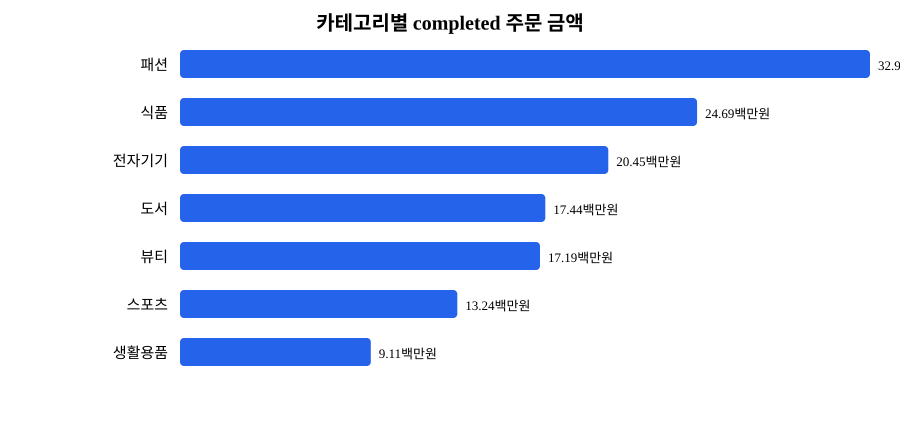

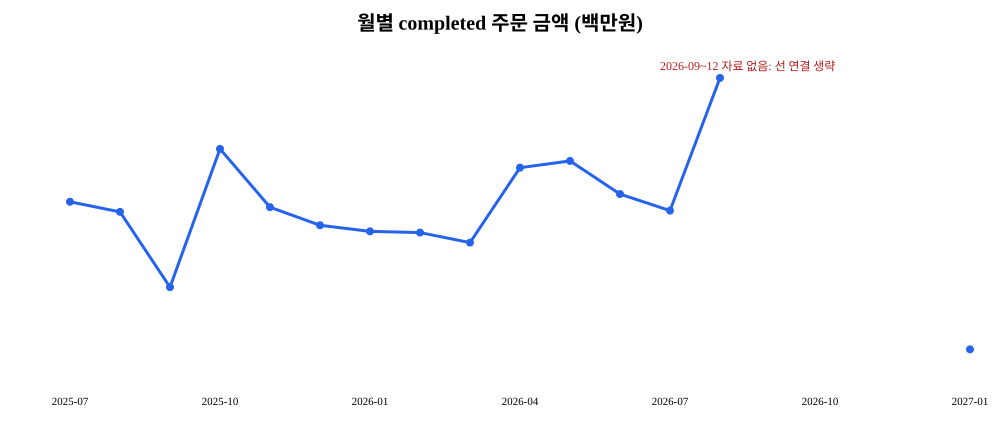

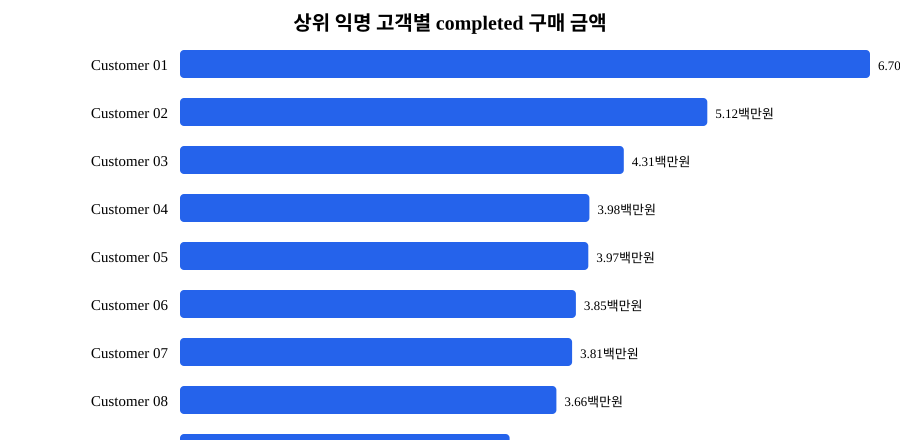

In [7]:
# 그래프는 검증 집계표에서만 만듭니다.
def bar_svg(labels, values, title):
    W,H,L,R,T,row_h = 900,440,185,35,55,42
    vmax=float(max(values)); body=[]
    for i,(label,value) in enumerate(zip(labels,values)):
        y=T+i*row_h; w=(W-L-R)*float(value)/vmax
        body.append(f'<text x="{L-12}" y="{y+20}" text-anchor="end" font-size="15">{label}</text>')
        body.append(f'<rect x="{L}" y="{y}" width="{w:.1f}" height="25" rx="4" fill="#2563eb"/>')
        body.append(f'<text x="{L+w+8:.1f}" y="{y+19}" font-size="13">{value/1e6:.2f}백만원</text>')
    return f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}"><rect width="100%" height="100%" fill="white"/><text x="{W/2}" y="30" text-anchor="middle" font-size="20" font-weight="bold">{title}</text>{"".join(body)}</svg>'

display(SVG(bar_svg(category_sales["category_clean"].tolist(),category_sales["total_sales"].tolist(),"카테고리별 completed 주문 금액")))

def monthly_svg(frame):
    W,H,L,R,T,B = 1000,440,70,30,55,75
    f = frame.sort_values("order_month").reset_index(drop=True)
    periods = pd.PeriodIndex(f["order_month"], freq="M")
    origin, end = periods.min().ordinal, periods.max().ordinal
    vals = f["total_sales"].astype(float).tolist()
    maxv = 18_000_000.0
    pts = []
    for period, value in zip(periods, vals):
        x = L + (period.ordinal-origin)/(end-origin)*(W-L-R)
        y = T + (maxv-value)*(H-T-B)/maxv
        pts.append((x,y,str(period),value,period.ordinal))
    paths, seg = [], []
    for i,p in enumerate(pts):
        if i and p[4]-pts[i-1][4] != 1:
            paths.append(" ".join(f'{"M" if j==0 else "L"} {q[0]:.1f} {q[1]:.1f}' for j,q in enumerate(seg)))
            seg = []
        seg.append(p)
    if seg:
        paths.append(" ".join(f'{"M" if j==0 else "L"} {q[0]:.1f} {q[1]:.1f}' for j,q in enumerate(seg)))
    path_svg = "".join(f'<path d="{d}" fill="none" stroke="#2563eb" stroke-width="3"/>' for d in paths)
    dots = "".join(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="4" fill="#2563eb"/>' for x,y,_,_,_ in pts)
    ticks = pd.period_range(periods.min(), periods.max(), freq="3M")
    tick_svg = "".join(
        f'<text x="{L+(p.ordinal-origin)/(end-origin)*(W-L-R):.1f}" y="{H-35}" text-anchor="middle" font-size="11">{p}</text>'
        for p in ticks
    )
    return f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}"><rect width="100%" height="100%" fill="white"/><text x="{W/2}" y="30" text-anchor="middle" font-size="20" font-weight="bold">월별 completed 주문 금액 (백만원)</text>{path_svg}{dots}{tick_svg}<text x="640" y="70" fill="#b91c1c" font-size="12">2026-09~12 자료 없음: 선 연결 생략</text></svg>'

display(SVG(monthly_svg(monthly_sales)))
display(SVG(bar_svg(customer_public.head(10)["customer_label"].tolist(),customer_public.head(10)["total_sales"].tolist(),"상위 익명 고객 구매 금액")))

## 8. 개인정보 점검

공개 고객 표에는 `customer_label, total_sales, order_count, avg_order_value`만 남깁니다. 원본 고객 ID·이름·이메일·전화번호·주소가 포함되지 않았는지 코드로 검사합니다. 익명 라벨은 금액 순위 기반이며 원본 ID를 단순 치환한 값이 아닙니다.

## 9. 최종 Validation

입력 전체의 FK 오류와 날짜 결측은 숨기지 않았습니다. 분석 코호트 안에서는 관계가 연결되고 날짜가 유효하며, `line_total` 관계와 금액 총합 검증을 통과했습니다. 최종 상태는 **제외·한계를 공개한 PASS**이며, 입력 전체 FK 무결성이 PASS라는 뜻은 아닙니다.

| 검증 항목 | 상태 | 근거 |
|---|---|---|
| 입력 PK 무결성 | PASS | 4개 PK 결측·중복 0 |
| 입력 FK 무결성 | **FAIL** | 고객 2, 주문 2, 상품 26 미매칭 |
| 분석 코호트 FK | PASS | 분석 사용 키 미매칭 0 |
| 병합 행 수 보존 | PASS | 752 → 752 |
| line_total 일치 | PASS | 752행 불일치 0 |
| 총액 일치 | PASS | 4개 합계 모두 135,046,000원 |
| 날짜 품질 | 주의 후 처리 | completed 6행·1,903,000원 날짜 결측 별도 보고 |
| 공개 고객 정보 | PASS | 원본 ID·직접 식별정보 제거

In [8]:
validation = pd.DataFrame([
    ["input_pk_integrity","PASS","4개 PK 결측·중복 0"],
    ["input_fk_integrity","FAIL","고객 2 / 주문 2 / 상품 26 미매칭"],
    ["analysis_cohort_fk_integrity","PASS","분석에 사용한 행의 필수 키 연결 완료"],
    ["merge_row_count_preserved","PASS" if merge_rows_preserved else "FAIL",f"{len(items)} → {len(joined)}"],
    ["line_total_consistency","PASS" if line_mismatch==0 else "FAIL",f"불일치 {line_mismatch}행"],
    ["completed_total_consistency","PASS" if totals["matches_source"].all() else "FAIL","네 총액 일치"],
    ["category_share_sum_pct","PASS" if np.isclose(category_sales["share_pct"].sum(),100) else "FAIL",f'{category_sales["share_pct"].sum():.2f}%'],
    ["missing_completed_dates","DISCLOSED",f"{date_rows}행 / {date_amount:,}원 별도 제외"],
    ["public_customer_columns_safe","PASS" if privacy_ok else "FAIL","원본 ID·직접 식별정보 없음"],
],columns=["check","status","evidence"]))
display(validation)

check                         status       evidence
input_pk_integrity            PASS         4개 PK 결측·중복 0
input_fk_integrity            FAIL         고객 2 / 주문 2 / 상품 26 미매칭
analysis_cohort_fk_integrity  PASS         필수 키 연결 완료 행만 사용
merge_row_count_preserved     PASS         752 → 752
line_total_consistency        PASS         불일치 0행
completed_total_consistency   PASS         네 총액 일치
category_share_sum_pct        PASS         100.00%
missing_completed_dates       DISCLOSED    6행 / 1,903,000원 별도 제외
public_customer_columns_safe  PASS         원본 ID·직접 식별정보 없음

## 10. LLM 활용 및 전체 재실행

- 사용 목적: 요구사항 정리, 검증 체크리스트·코드 작성 보조, 해석 문장 검토
- Prompt 요약: PK/FK·병합·completed 범위·합계·날짜·개인정보를 점검하고 관찰과 해석을 분리해 정리
- 반영: 검증 순서와 집계 익명화 방식 반영
- 사람의 확인: 저장소 CSV를 다시 읽어 행 수, FK 개수, 산식, 날짜 결측 금액, 총합을 대조
- 원본 고객 행 단위 이름·ID를 LLM에 제공하지 않았으며 출력은 집계와 순위 라벨만 포함

저장소 루트에서 이 Notebook을 위에서부터 끝까지 실행하면 Chapter 05 raw CSV에서 검증·분석·그래프를 다시 만들 수 있습니다. 실행 환경에는 pandas, numpy, IPython이 필요합니다. 재실행 가능한 흐름은 같은 기준으로 수치를 재생성하고 오류가 생긴 셀을 찾아 수정하게 해 분석 신뢰성을 높입니다.

## 11. 최종 프로젝트 요약

1. **관찰:** completed 입력 141,340,000원 중 키 오류·날짜 결측 6,294,000원을 제외해 비교 가능한 코호트 135,046,000원을 만들었습니다. **의미:** 키 관계를 확인하지 않으면 서로 다른 데이터 범위가 결과에 섞일 수 있습니다. **한계:** 제외 행은 원천 확인 전까지 실제 누락과 잘못된 참조를 구별하기 어렵습니다.
2. **관찰:** 검증 코호트에서는 패션 금액이 32,940,000원으로 가장 컸습니다. **의미:** 후속으로 수량·단가·상품별 기여를 점검할 후보입니다. **한계:** 금액 합계는 마진이나 선호를 나타내지 않습니다.
3. **관찰:** 2026년 8월 금액은 16,668,000원·15건으로 관찰 월 중 가장 컸습니다. **의미:** 월별 지표의 추가 추적 가치가 있습니다. **한계:** 이후 4개월 자료 공백과 2027년 1월 1건만으로 추세나 계절성을 주장할 수 없습니다.

### 다음 분석 제안
- 미매칭 FK의 원천 생성 규칙과 정정 가능성 확인
- 날짜 결측 completed 주문 2건의 원본 시점 확인 후 월별 민감도 분석
- 원가·할인·반품 데이터가 확보되면 총매출과 수익성 분리